### ***Corrective RAG***
- ***Corrective RAG evaluates the retrieved documents and, if they are insufficient, corrects the retrieval process before generating the final answer.***

In [1]:
import warnings,time
warnings.filterwarnings("ignore")

# Document Loader & Vector Store
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS 

# Mistral AI Integrations
from langchain_mistralai import ChatMistralAI, MistralAIEmbeddings

# Core Utilities & Prompts
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

In [2]:
from langgraph.graph import StateGraph,START,END 
from typing import List, TypedDict
from dotenv import find_dotenv,load_dotenv

In [3]:
docs = (
    PyPDFLoader("../_notes/ML_book.pdf").load()
)

In [4]:
len(docs)

392

In [5]:
# Perform Chunking
chunks = RecursiveCharacterTextSplitter(chunk_size=700,chunk_overlap=170).split_documents(docs)

# clean text 
for d in chunks:
    d.page_content = d.page_content.encode("utf-8","ignore").decode("utf-8","ignore")

In [6]:
len(chunks)

1377

In [7]:
load_dotenv(find_dotenv(usecwd=True))

True

In [8]:
import os 

# Check if the key was loaded properly
api_key = os.getenv("MISTRAL_API_KEY")
if not api_key:
    raise ValueError("MISTRAL_API_KEY not found! Check your .env file location.")

# Index 
embeddings = MistralAIEmbeddings(model="mistral-embed",mistral_api_key=api_key)
vector_store = FAISS.from_documents(chunks,embeddings)
vector_store.save_local("vector_store")

In [ ]:
# now we can retrived our data 
retirever = vector_store.as_retriever(search_type='similarity',search_kwargs={'k':4})

from langchain_groq import ChatGroq
# LLm Provider 
llm = ChatGroq(model="openai/gpt-oss-120b",temperature=0.2,streaming=True)

In [17]:
# define oue schema 
class State(TypedDict):
     question:str
     docs:List[Document]
     answer:str 

In [18]:
def retireve(state):
     q = state["question"]
     return {'docs':retirever.invoke(q)}

In [19]:
# Prompt 
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)

def generate_ans(state):
    context = "\n\n".join(d.page_content for d in state["docs"])
    out = (prompt | llm).invoke({"question": state["question"], "context": context})
    return {"answer": out.content}

In [20]:
graph = StateGraph(State)
graph.add_node("retireve",retireve)
graph.add_node("generate_ans",generate_ans)
graph.add_edge(START,"retireve")
graph.add_edge("retireve","generate_ans")
graph.add_edge("generate_ans",END)
app = graph.compile()

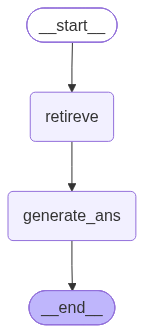

In [21]:
app

In [22]:
res = app.invoke({"question": "What is Transformers", "docs": [], "answer": ""})
print(res["answer"])

In the context provided, a **transformer** is a step in a scikit‑learn pipeline that implements a `fit` method (to learn any necessary parameters from the training data) and a `transform` method (to convert the input data into a new representation).  

- Transformers take the output of the previous step, apply some transformation—such as scaling, dimensionality reduction (e.g., PCA), or any custom operation—and pass the transformed data onward in the pipeline.  
- They are called “transformers” because their primary purpose is to **transform** the data rather than to make predictions.  
- Examples mentioned include a scaler, PCA, or any custom class that inherits from `TransformerMixin` and defines `fit` and `transform`.  

Thus, transformers are the building blocks that reshape or re‑represent data within a pipeline before it reaches a final estimator (like a classifier or regressor).


In [23]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

The process is illustrated in Figure 6-3  for two transformers, T1 and T2, and a
classifier (called Classifier).
Figure 6-3. Overview of the pipeline training and prediction process
The pipeline is actually even more general than this. There is no requirement for the
last step in a pipeline to have a predict function, and we could create a pipeline just
containing, for example, a scaler and PCA. Then, because the last step ( PCA) has a
transform method, we could call transform on the pipeline to get the output of
PCA.transform applied to the data that was processed by the previous step. The last
step of a pipeline is only required to have a fit method.
****************************************************************************************************
of the dataset and clustering.
Unsupervised transformations of a dataset are algorithms that create a new representa‐
tion of the data which might be easier for humans or other machine learning algo‐
rithms to understand compared to the o